In [1]:
from pathlib import Path
import pandas as pd

files = sorted(Path("phaseclass").glob("*.csv"))

print("Total files:", len(files))
print()

for file in files:
    df = pd.read_csv(file)

    print("=" * 70)
    print("FILE:", file.name)
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print()
    print(df.columns.tolist())
    print()
    print(df.head(2).to_string(index=False))

Total files: 22

FILE: 2023-10_1_phaseclass.csv
Rows: 23156
Columns: 23

['t_s', 'Vx_mps', 'Vy_mps', 'yawRate_radps', 'roadWheelAngle_rad', 'ayCG_mps2', 'axCG_mps2', 'throttleCmd_percent', 'brake_fl_bar', 'brake_fr_bar', 'brake_rl_bar', 'brake_rr_bar', 'engineTorque_Nm', 'engine_rpm', 'wheelspeed_fl', 'wheelspeed_fr', 'wheelspeed_rl', 'wheelspeed_rr', 'LSDengage_percent', 'rollRate_radps', 'pitchRate_radps', 'speed_mps', 'beta_deg']

     t_s   Vx_mps    Vy_mps  yawRate_radps  roadWheelAngle_rad  ayCG_mps2  axCG_mps2  throttleCmd_percent  brake_fl_bar  brake_fr_bar  brake_rl_bar  brake_rr_bar  engineTorque_Nm  engine_rpm  wheelspeed_fl  wheelspeed_fr  wheelspeed_rl  wheelspeed_rr  LSDengage_percent  rollRate_radps  pitchRate_radps  speed_mps  beta_deg
0.000000 5.567467 -0.040651       0.011868           -0.000369   0.907078  -0.767641                100.0           0.0           0.0           0.0           0.0              -25        1373      17.374214       17.35456       17.45283   

In [2]:
from pathlib import Path
import pandas as pd

files = sorted(Path("phaseclass").glob("*.csv"))

summary = []

for file in files:
    df = pd.read_csv(file)

    summary.append({
        "file": file.name,
        "rows": len(df),
        "missing_beta": df["beta_deg"].isna().sum(),
        "missing_speed": df["speed_mps"].isna().sum(),
        "min_speed": df["speed_mps"].min(),
        "max_speed": df["speed_mps"].max(),
        "min_beta": df["beta_deg"].min(),
        "max_beta": df["beta_deg"].max(),
        "mean_beta": df["beta_deg"].mean()
    })

summary_df = pd.DataFrame(summary)

summary_df

,file,rows,missing_beta,missing_speed,min_speed,max_speed,min_beta,max_beta,mean_beta
0,2023-10_1_phaseclass.csv,23156,0,0,3.055259,32.002351,-4.435982,3.194499,-0.774569
1,2023-10_2_phaseclass.csv,22866,465,0,0.000000,32.050610,-12.956911,9.521428,-0.796284
2,2023-10_3_phaseclass.csv,23156,0,0,3.055259,32.002351,-4.435982,3.194499,-0.774569
3,2023-10_4_phaseclass.csv,23345,2385,0,0.000000,32.106267,-4.639771,23.688227,-0.620275
4,2023-10_5_phaseclass.csv,46484,496,0,0.000000,32.016384,-12.277322,10.123096,-0.751065
5,2023-10_6_phaseclass.csv,22115,0,0,0.233217,32.019192,-6.724990,10.256433,-0.649157
6,2023-10_7_phaseclass.csv,26996,1146,0,0.000000,31.855539,-7.539671,12.086354,-0.683458
7,2023-10_8_phaseclass.csv,42365,665,0,0.000000,32.075426,-12.396852,4.698096,-0.917373
8,2023-10_9_phaseclass.csv,23844,744,0,0.000000,31.983932,-12.045495,8.107084,-0.844156
9,2023-10_phaseclass.csv,22866,465,0,0.000000,32.050610,-12.956911,9.521428,-0.796284


In [3]:
for file in files:
    df = pd.read_csv(file)

    print(
        file.name,
        "| β min:",
        round(df["beta_deg"].min(), 2),
        "| β max:",
        round(df["beta_deg"].max(), 2),
        "| β mean:",
        round(df["beta_deg"].mean(), 2),
        "| β std:",
        round(df["beta_deg"].std(), 2)
    )

2023-10_1_phaseclass.csv | β min: -4.44 | β max: 3.19 | β mean: -0.77 | β std: 1.27
2023-10_2_phaseclass.csv | β min: -12.96 | β max: 9.52 | β mean: -0.8 | β std: 1.34
2023-10_3_phaseclass.csv | β min: -4.44 | β max: 3.19 | β mean: -0.77 | β std: 1.27
2023-10_4_phaseclass.csv | β min: -4.64 | β max: 23.69 | β mean: -0.62 | β std: 1.75
2023-10_5_phaseclass.csv | β min: -12.28 | β max: 10.12 | β mean: -0.75 | β std: 1.42
2023-10_6_phaseclass.csv | β min: -6.72 | β max: 10.26 | β mean: -0.65 | β std: 1.78
2023-10_7_phaseclass.csv | β min: -7.54 | β max: 12.09 | β mean: -0.68 | β std: 1.53
2023-10_8_phaseclass.csv | β min: -12.4 | β max: 4.7 | β mean: -0.92 | β std: 1.6
2023-10_9_phaseclass.csv | β min: -12.05 | β max: 8.11 | β mean: -0.84 | β std: 1.24
2023-10_phaseclass.csv | β min: -12.96 | β max: 9.52 | β mean: -0.8 | β std: 1.34
2023-11_10_phaseclass.csv | β min: -6.1 | β max: 15.57 | β mean: 0.37 | β std: 1.18
2023-11_11_phaseclass.csv | β min: -7.26 | β max: 8.27 | β mean: -0.03 | β

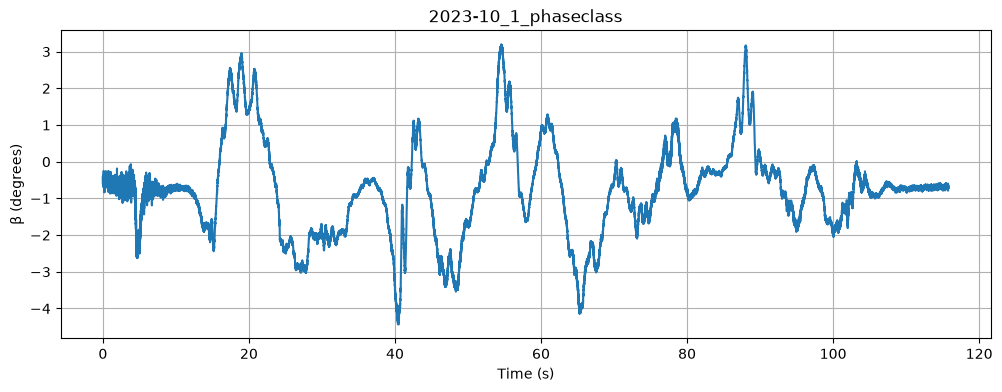

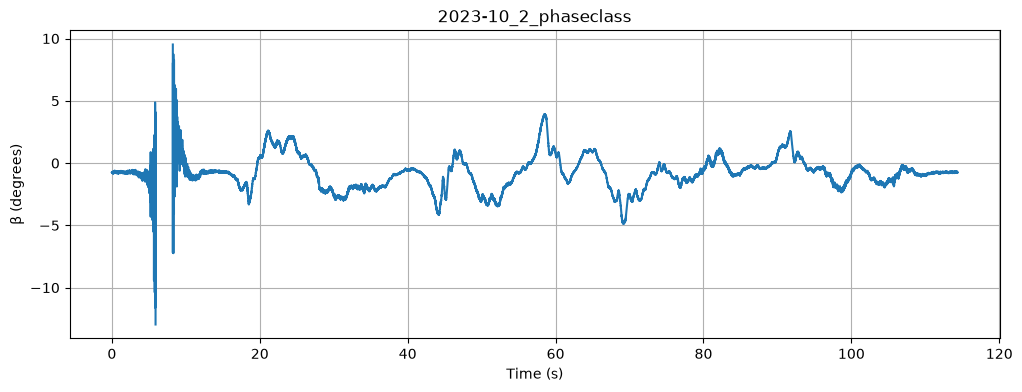

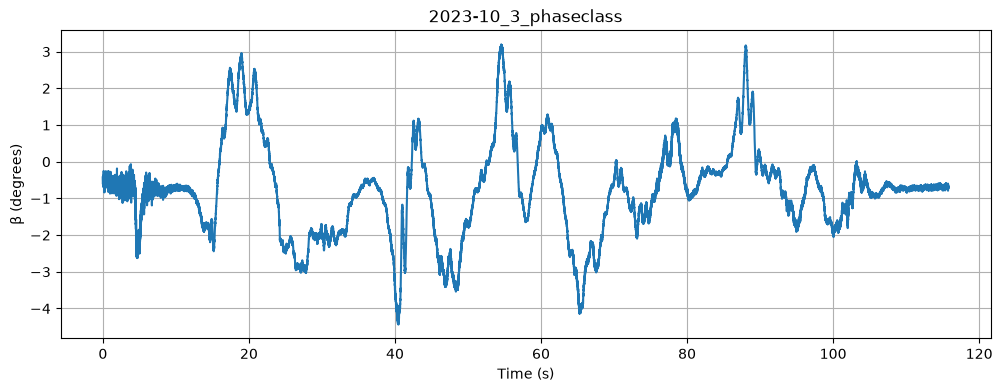

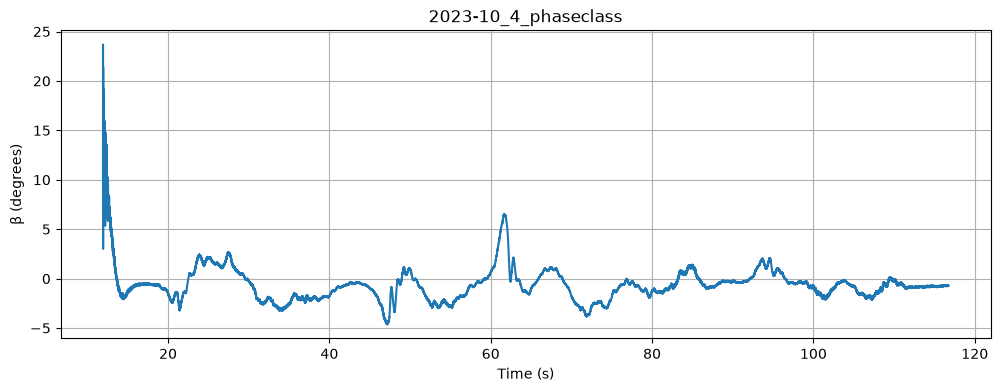

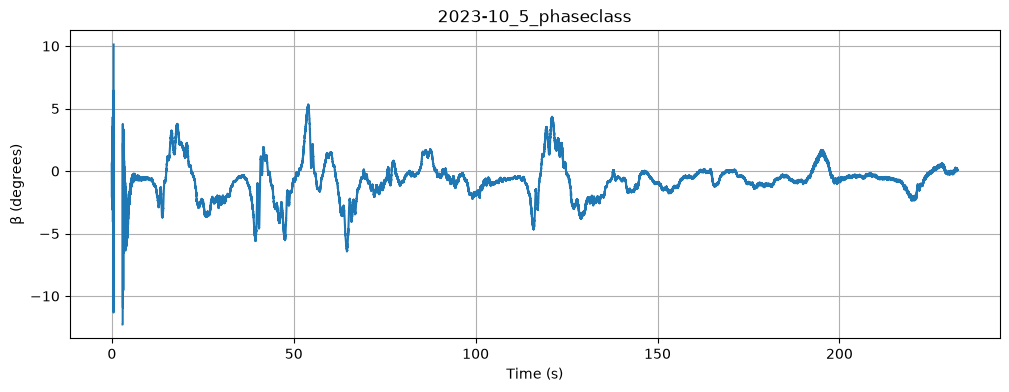

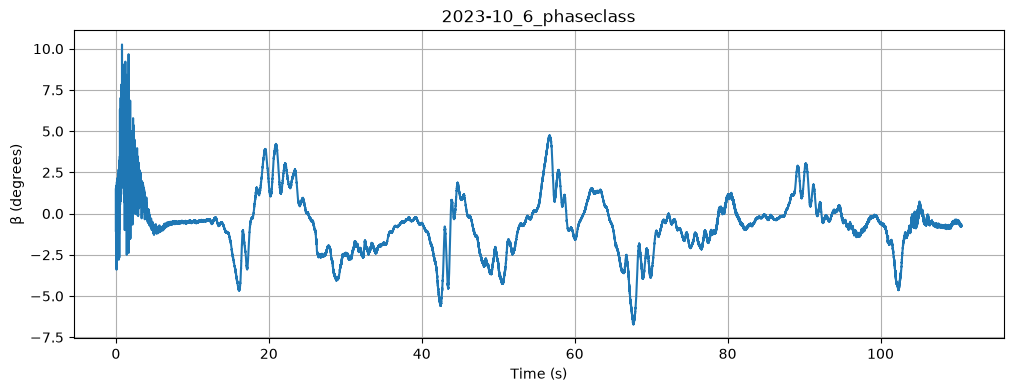

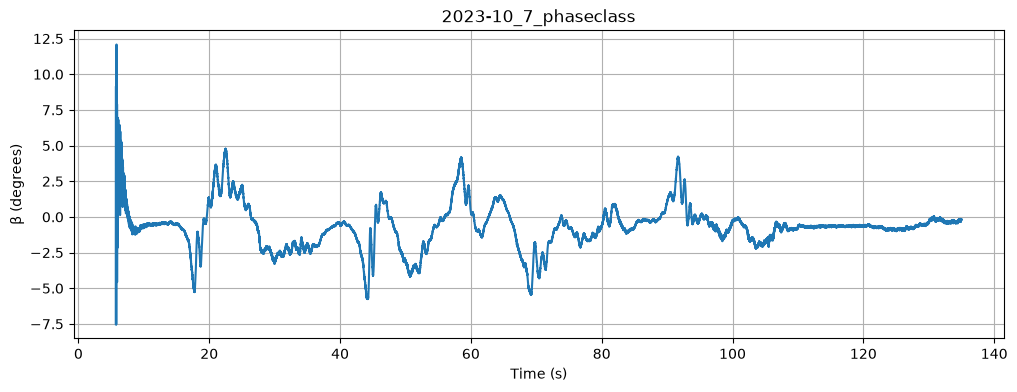

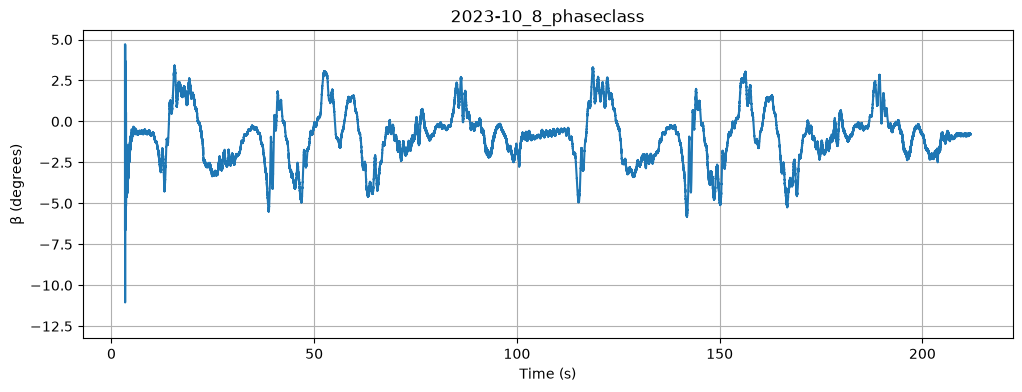

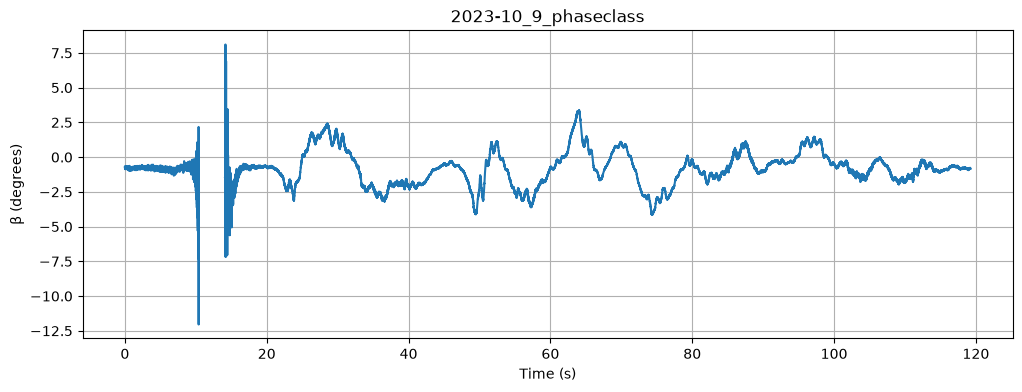

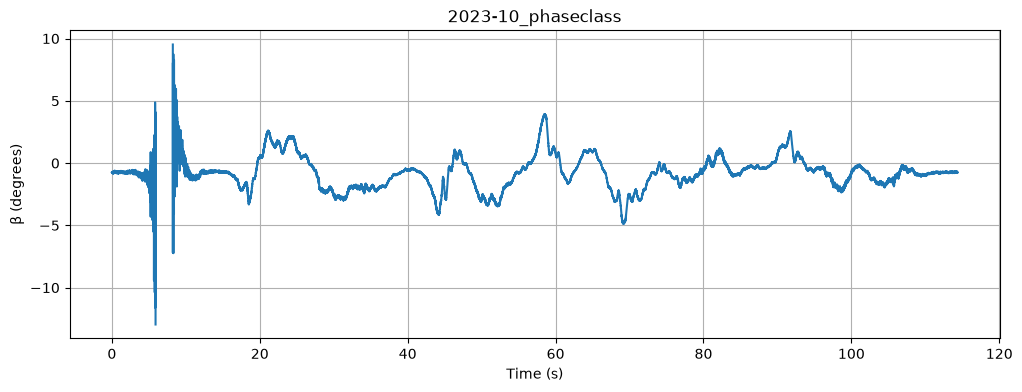

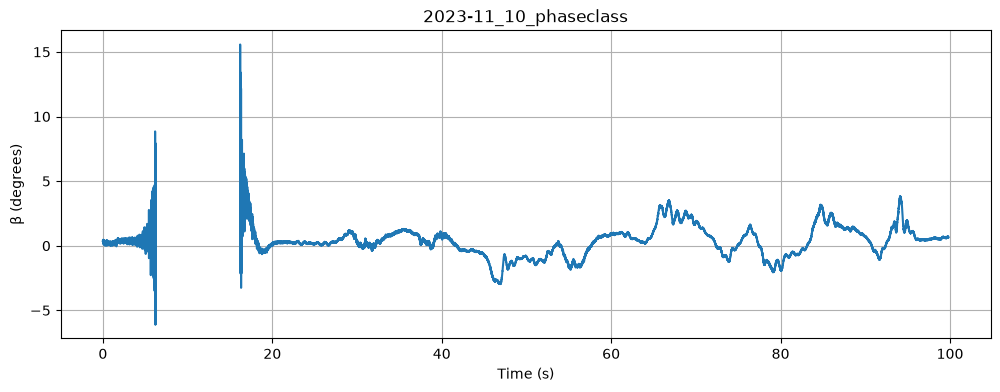

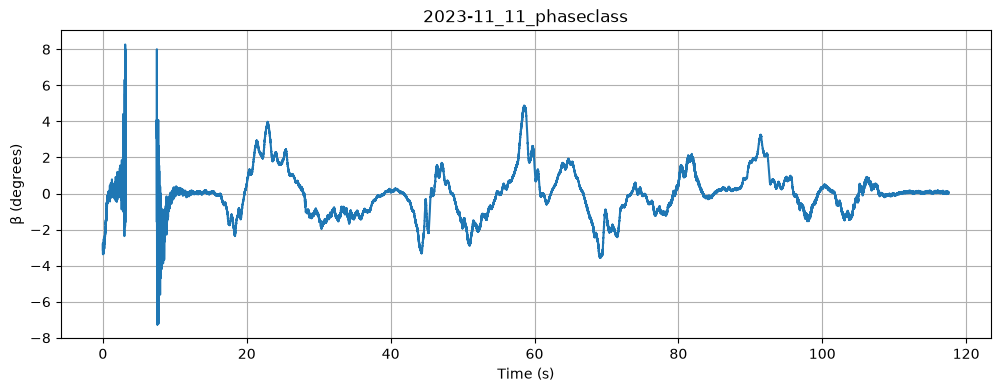

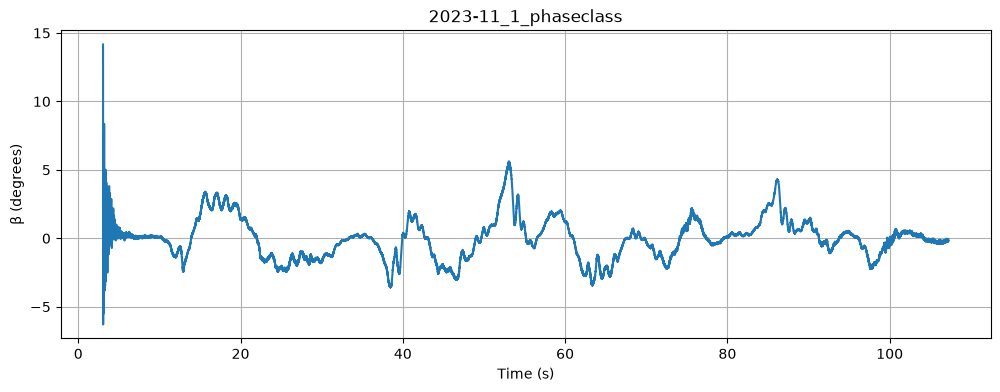

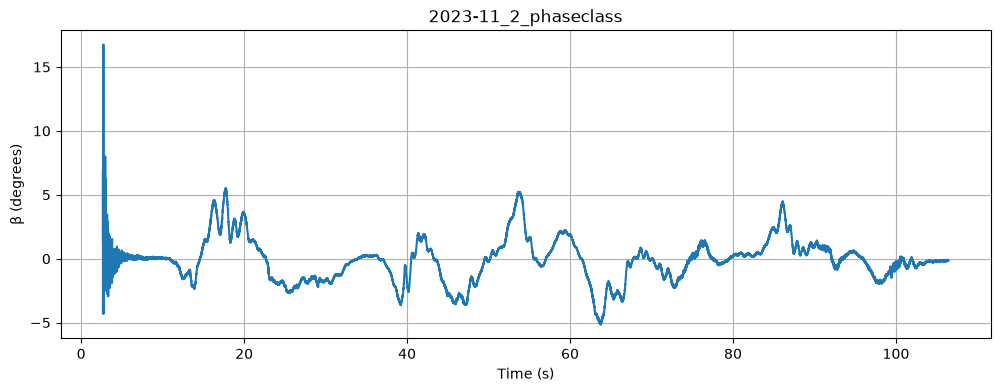

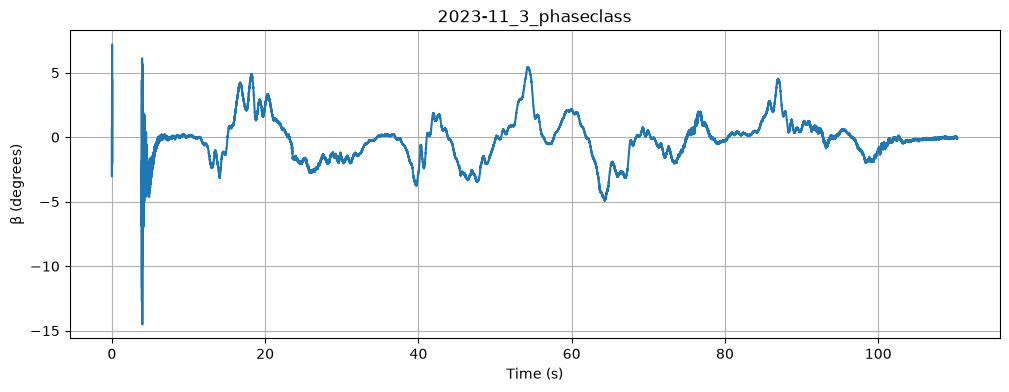

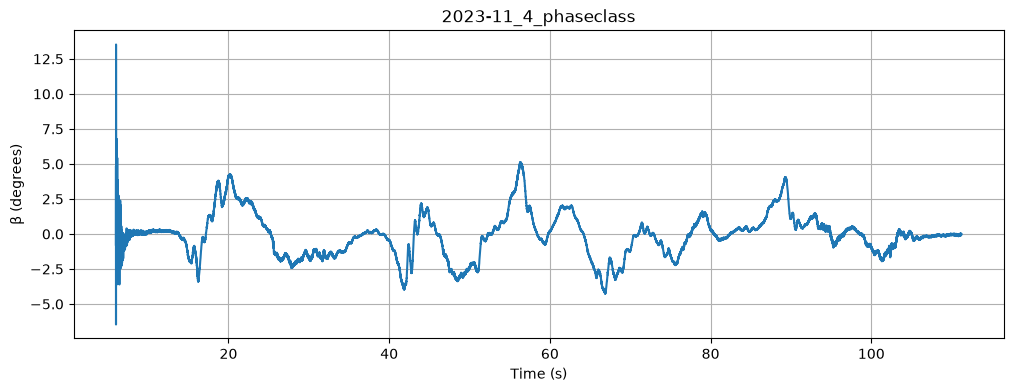

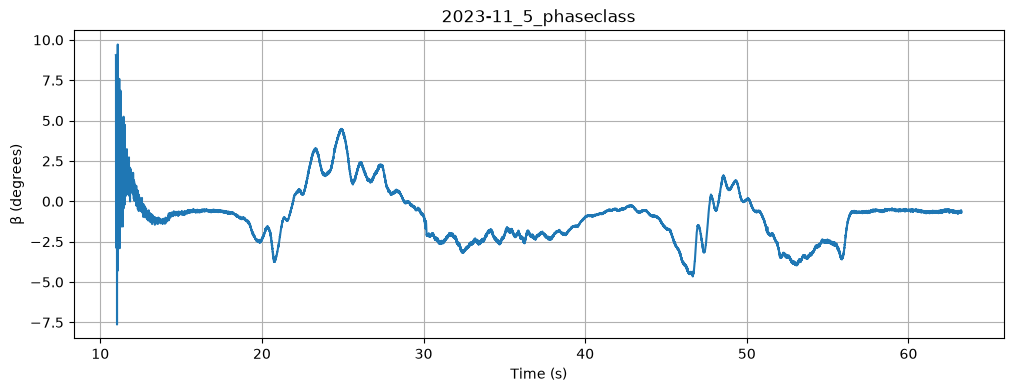

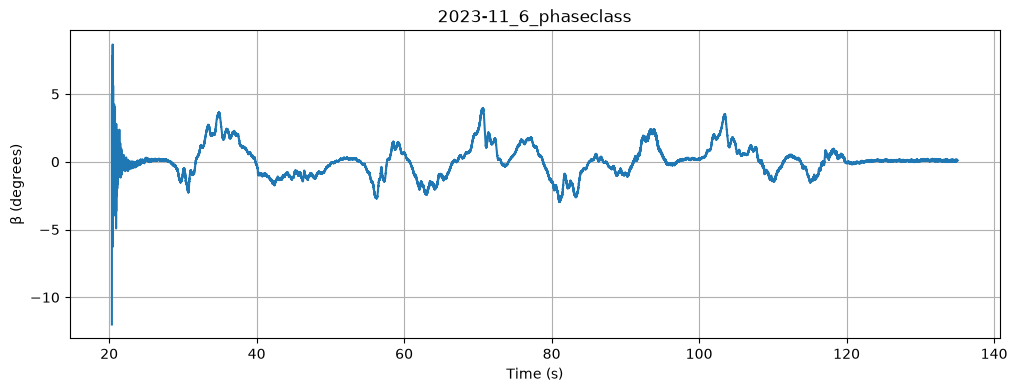

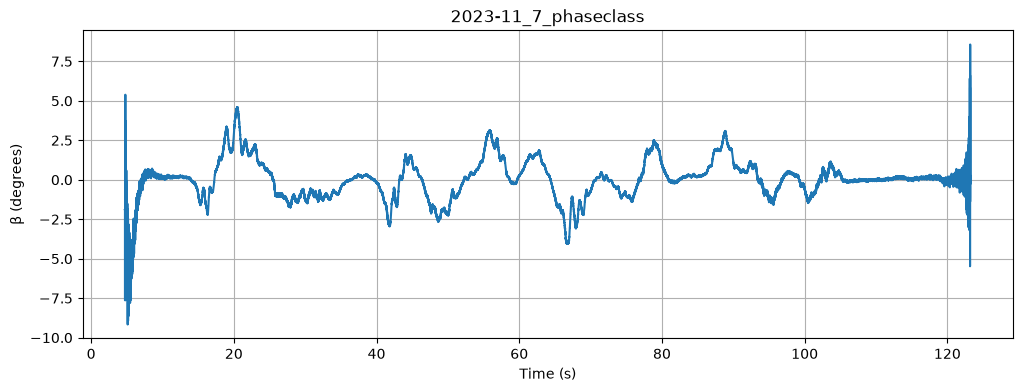

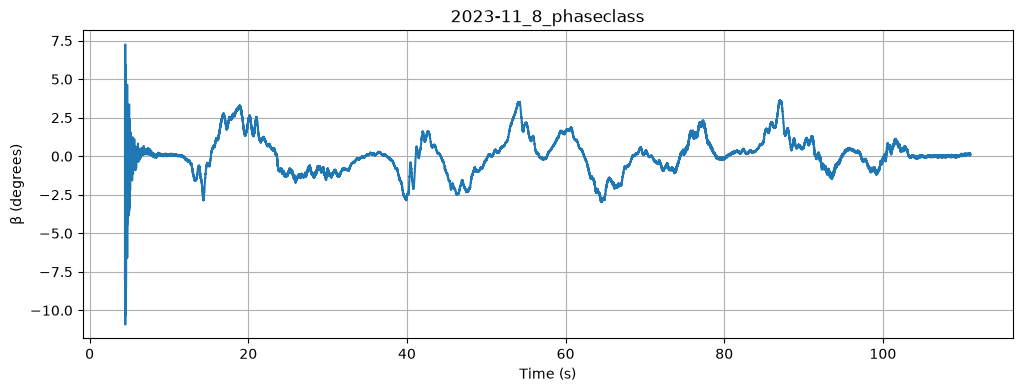

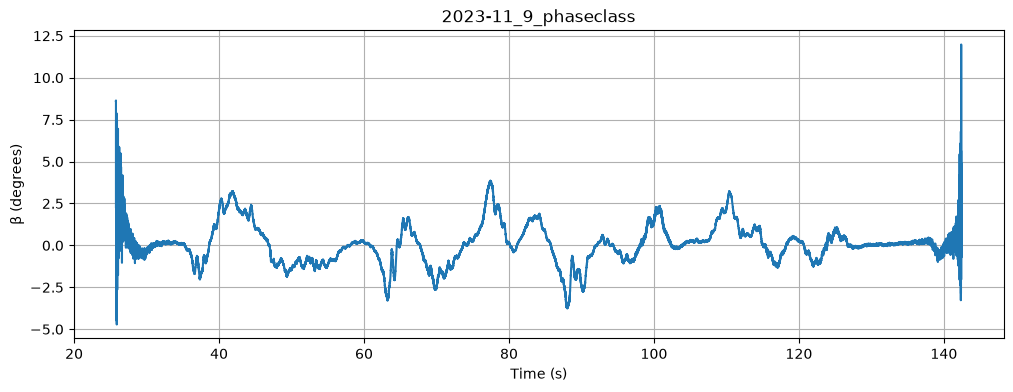

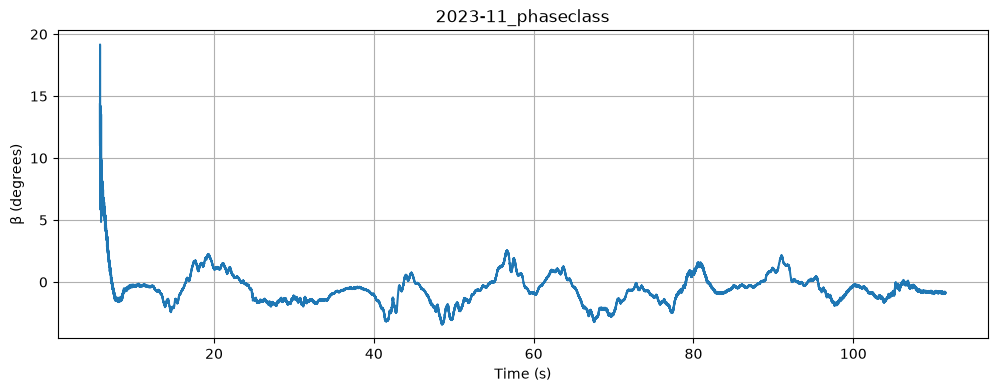

In [5]:
import matplotlib.pyplot as plt

for file in files:
    df = pd.read_csv(file)

    plt.figure(figsize=(12, 4))
    plt.plot(df["t_s"], df["beta_deg"])
  
    plt.xlabel("Time (s)")
    plt.ylabel("β (degrees)")
    plt.title(file.stem)
    plt.grid()
    plt.show()

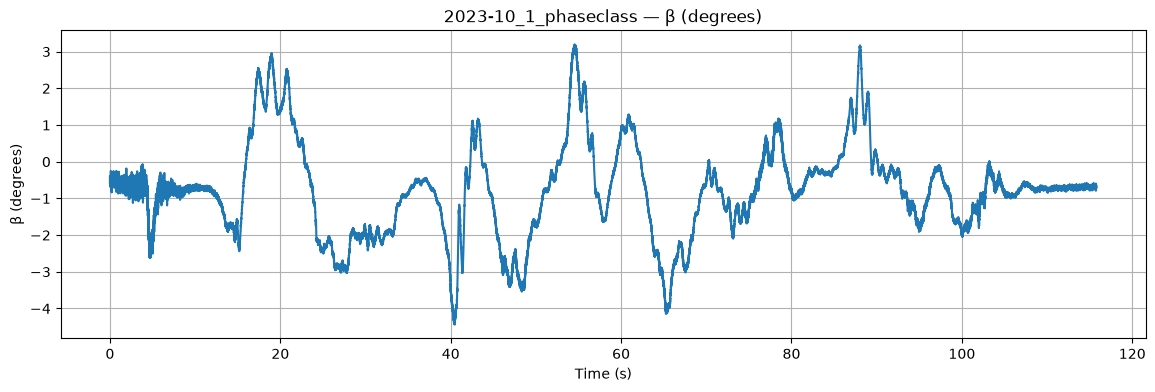

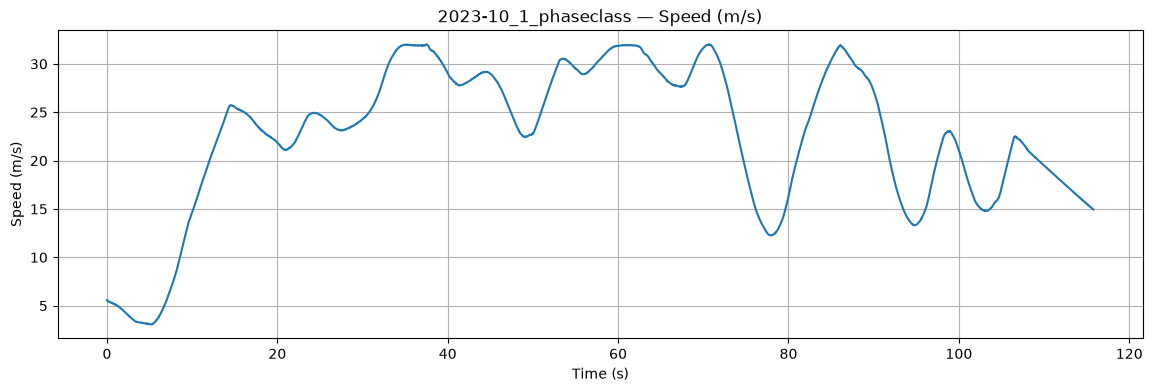

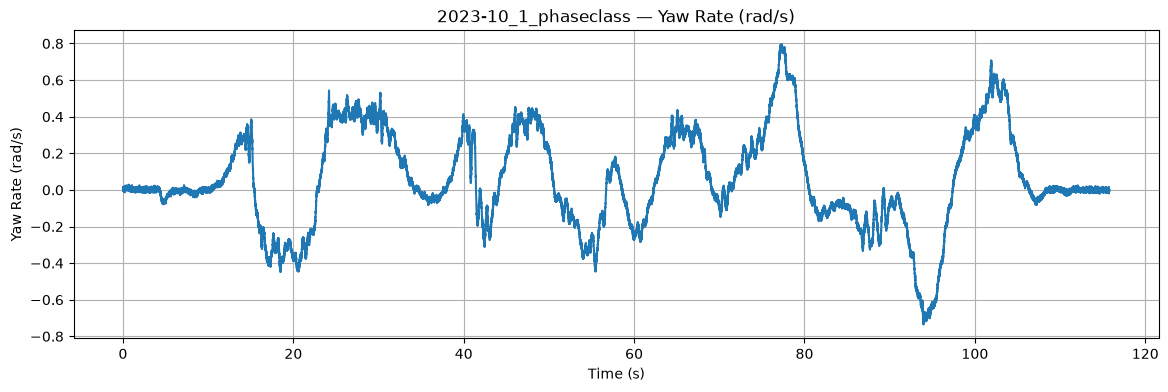

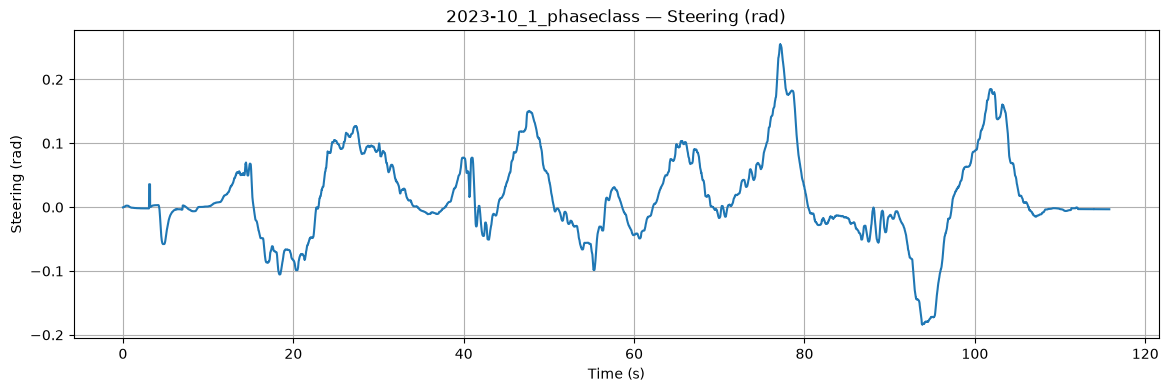

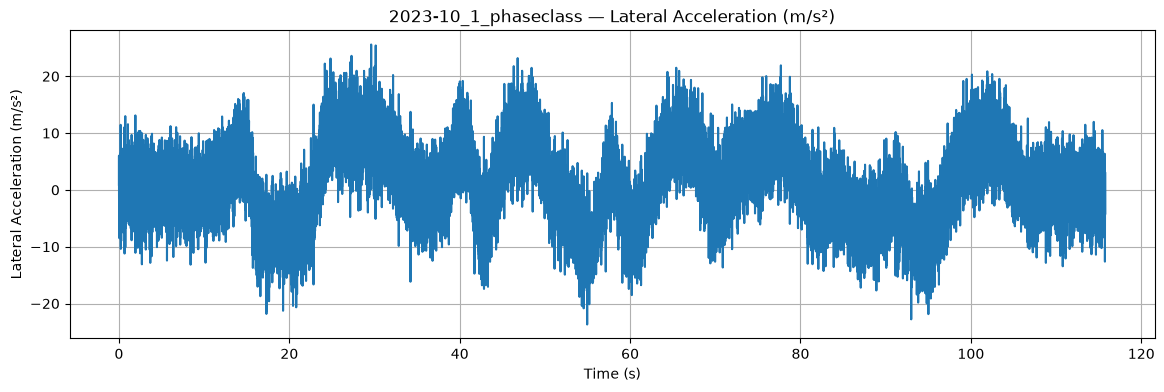

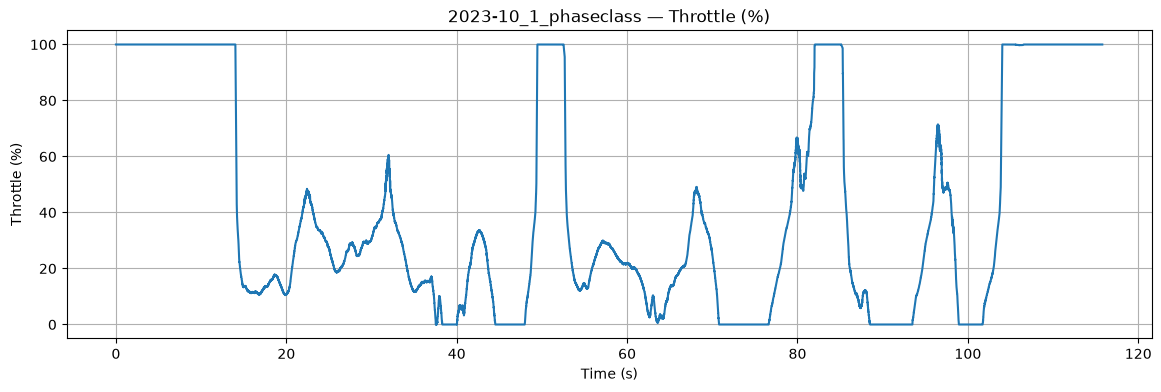

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

files = sorted(Path("phaseclass").glob("*.csv"))
df = pd.read_csv(files[0])

signals = [
    ("beta_deg", "β (degrees)"),
    ("speed_mps", "Speed (m/s)"),
    ("yawRate_radps", "Yaw Rate (rad/s)"),
    ("roadWheelAngle_rad", "Steering (rad)"),
    ("ayCG_mps2", "Lateral Acceleration (m/s²)"),
    ("throttleCmd_percent", "Throttle (%)")
]

for column, ylabel in signals:
    plt.figure(figsize=(14, 4))
    plt.plot(df["t_s"], df[column])
    plt.xlabel("Time (s)")
    plt.ylabel(ylabel)
    plt.title(f"{files[0].stem} — {ylabel}")
    plt.grid()
    plt.show()

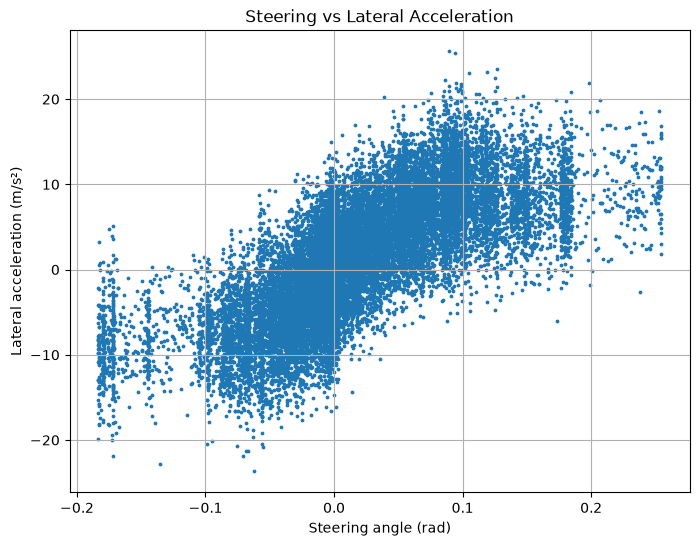

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

files = sorted(Path("phaseclass").glob("*.csv"))
df = pd.read_csv(files[0])

plt.figure(figsize=(8, 6))
plt.scatter(
    df["roadWheelAngle_rad"],
    df["ayCG_mps2"],
    s=3
)

plt.xlabel("Steering angle (rad)")
plt.ylabel("Lateral acceleration (m/s²)")
plt.title("Steering vs Lateral Acceleration")
plt.grid()
plt.show()

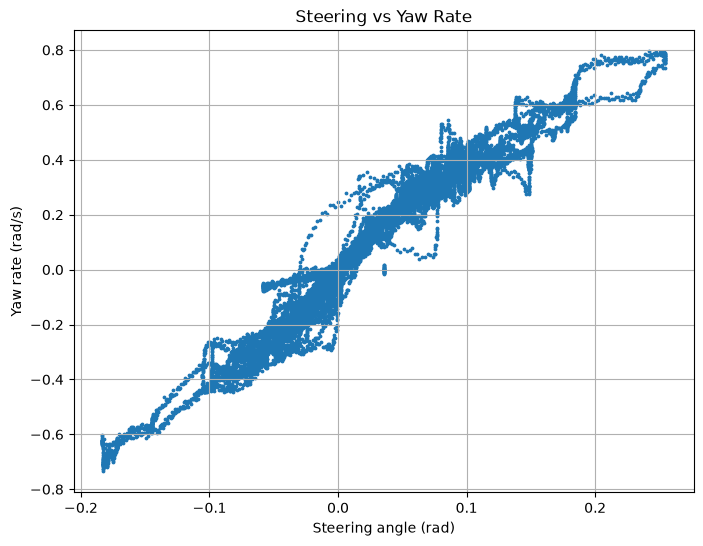

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["roadWheelAngle_rad"],
    df["yawRate_radps"],
    s=3
)

plt.xlabel("Steering angle (rad)")
plt.ylabel("Yaw rate (rad/s)")
plt.title("Steering vs Yaw Rate")
plt.grid()
plt.show()

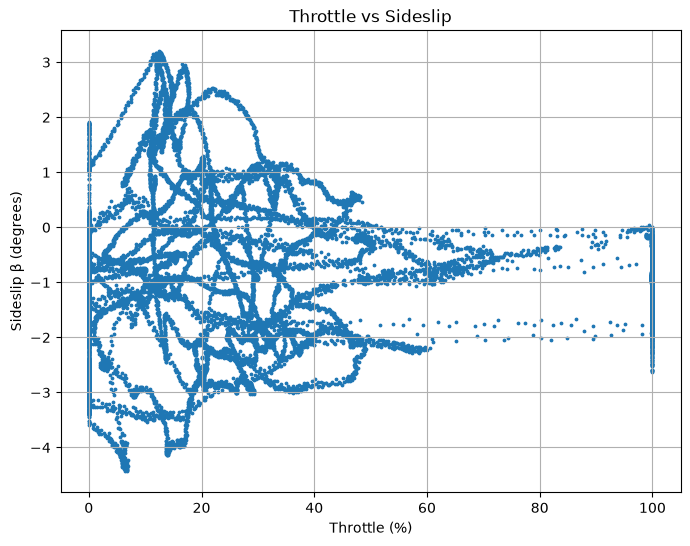

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["throttleCmd_percent"],
    df["beta_deg"],
    s=3
)

plt.xlabel("Throttle (%)")
plt.ylabel("Sideslip β (degrees)")
plt.title("Throttle vs Sideslip")
plt.grid()
plt.show()